# Thực nghiệm So sánh PhoBERT và viBERT trên Bài toán Phân loại Cảm xúc Tiếng Việt (UIT-VSFC)

**Mục tiêu thực nghiệm:**
- Cài đặt và chạy thực nghiệm fine-tuning hai mô hình tiền huấn luyện đơn ngữ tiếng Việt tiêu biểu: **PhoBERT** (`vinai/phobert-base-v2` hoặc `vinai/phobert-base`) và **viBERT** (`FPTAI/vibert-base-cased`).
- Minh họa trực quan sự khác biệt cốt lõi về **quy trình tiền xử lý (Word-level Segmentation vs. Syllable-level)** giữa hai mô hình:
  - **PhoBERT:** Yêu cầu tách từ ghép tiếng Việt bằng `pyvi` / `underthesea` / `vncorenlp` (ví dụ: `"sinh viên"` $\rightarrow$ `"sinh_viên"`) trước khi đưa vào tokenizer.
  - **viBERT:** Nhận trực tiếp văn bản thô ở mức âm tiết (syllable-level), không cần bước tách từ trung gian.
- Huấn luyện, đánh giá trên tập dữ liệu chuẩn tiếng Việt **UIT-VSFC** (Vietnamese Students' Feedback Corpus - 3 nhãn: Tiêu cực, Trung tính, Tích cực) và xuất bảng/biểu đồ so sánh **Accuracy, Macro F1-score, thời gian huấn luyện và tốc độ suy luận (Inference Latency)**.

## 1. Cài đặt thư viện cần thiết
Chạy cell dưới đây để cài đặt `transformers`, `datasets`, `accelerate`, `pyvi` (tách từ tiếng Việt nhẹ, không cần cài Java như VnCoreNLP, cực kỳ thuận tiện trên Google Colab), `scikit-learn`, `matplotlib`, và `seaborn`.

In [1]:
!pip install -q transformers datasets accelerate pyvi scikit-learn matplotlib seaborn

## 2. Import thư viện & Thiết lập cấu hình chung

In [2]:
import os
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from pyvi import ViTokenizer
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# Tắt cảnh báo tokenizer parallelism & wandb
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

# Cố định seed để tái lập kết quả thực nghiệm
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Thiết bị đang sử dụng: cuda
GPU: Tesla T4


## 3. Tải và Khám phá Dữ liệu thực nghiệm (UIT-VSFC)
Chúng ta sử dụng bộ dữ liệu **UIT-VSFC** (gồm ~16.000 câu phản hồi của sinh viên tiếng Việt) với 3 nhãn cảm xúc:
- `0`: Tiêu cực (Negative)
- `1`: Trung tính (Neutral)
- `2`: Tích cực (Positive)

*(Lưu ý: Notebook có tích hợp chế độ `FAST_DEMO_MODE = True` lấy mẫu con đại diện để chạy thử nghiệm nhanh trong ~2–3 phút trên GPU T4; bạn có thể đặt `FAST_DEMO_MODE = False` để chạy toàn bộ 100% tập dữ liệu)*.

In [3]:
# Tải dataset UIT-VSFC trực tiếp từ nhánh Parquet trên Hugging Face Hub
parquet_files = {
    "train": "hf://datasets/uitnlp/vietnamese_students_feedback@refs/convert/parquet/default/train/*.parquet",
    "validation": "hf://datasets/uitnlp/vietnamese_students_feedback@refs/convert/parquet/default/validation/*.parquet",
    "test": "hf://datasets/uitnlp/vietnamese_students_feedback@refs/convert/parquet/default/test/*.parquet",
}
dataset = load_dataset("parquet", data_files=parquet_files)
print(dataset)

LABEL_NAMES = ["Tiêu cực (0)", "Trung tính (1)", "Tích cực (2)"]
NUM_LABELS = 3

# Xem thử 5 mẫu dữ liệu gốc
df_sample = pd.DataFrame(dataset["train"][:5])
df_sample["label_name"] = df_sample["sentiment"].apply(lambda x: LABEL_NAMES[x])
display(df_sample[["sentence", "sentiment", "label_name"]])

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

default/validation/0000.parquet: downloading bytes:           |  0.00B            

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  134kB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 11426
    })
    validation: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 1583
    })
    test: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 3166
    })
})


,sentence,sentiment,label_name
0,slide giáo trình đầy đủ .,2,Tích cực (2)
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,Tích cực (2)
2,đi học đầy đủ full điểm chuyên cần .,0,Tiêu cực (0)
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,Tiêu cực (0)
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,Tích cực (2)


In [4]:
# Cấu hình chế độ chạy thực nghiệm
FAST_DEMO_MODE = True  # Đặt False để chạy toàn bộ dataset (11,426 train / 1,583 val / 3,166 test)

if FAST_DEMO_MODE:
    train_raw = dataset["train"].shuffle(seed=SEED).select(range(2400))
    val_raw   = dataset["validation"].shuffle(seed=SEED).select(range(400))
    test_raw  = dataset["test"].shuffle(seed=SEED).select(range(600))
    EPOCHS = 3
    print("[CHẾ ĐỘ DEMO NHANH] Đang dùng 2,400 mẫu train | 400 mẫu val | 600 mẫu test")
else:
    train_raw = dataset["train"]
    val_raw   = dataset["validation"]
    test_raw  = dataset["test"]
    EPOCHS = 4
    print("[CHẾ ĐỘ FULL DATASET] Đang dùng toàn bộ dữ liệu UIT-VSFC")

[CHẾ ĐỘ DEMO NHANH] Đang dùng 2,400 mẫu train | 400 mẫu val | 600 mẫu test


## 4. Trực quan hóa sự khác biệt cơ chế Tách từ giữa PhoBERT và viBERT
Trước khi huấn luyện, hãy kiểm tra cách hai mô hình xử lý cùng một câu tiếng Việt để thấy rõ sự khác biệt giữa **Word-level Segmentation (PhoBERT)** và **Syllable-level WordPiece (viBERT)**.

In [5]:
PHOBERT_MODEL_NAME = "vinai/phobert-base-v2"
VIBERT_MODEL_NAME  = "FPTAI/vibert-base-cased"

phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_MODEL_NAME)
vibert_tokenizer  = AutoTokenizer.from_pretrained(VIBERT_MODEL_NAME)

sample_text = "Giảng viên giảng bài rất nhiệt tình và dễ hiểu, tài liệu học tập đầy đủ."

# 1. Tiền xử lý cho PhoBERT: Tách từ ghép tiếng Việt bằng ViTokenizer
segmented_text = ViTokenizer.tokenize(sample_text)
phobert_tokens = phobert_tokenizer.tokenize(segmented_text)

# 2. Tiền xử lý cho viBERT: Đưa trực tiếp câu gốc ở mức âm tiết
vibert_tokens  = vibert_tokenizer.tokenize(sample_text)

print("Câu gốc:", sample_text)
print("-" * 80)
print("Sau khi tách từ (cho PhoBERT):", segmented_text)
print("Tokens của PhoBERT (Word-level BPE):", phobert_tokens)
print("-" * 80)
print("Tokens của viBERT (Syllable-level WordPiece):", vibert_tokens)

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/255k [00:00<?, ?B/s]

Câu gốc: Giảng viên giảng bài rất nhiệt tình và dễ hiểu, tài liệu học tập đầy đủ.
--------------------------------------------------------------------------------
Sau khi tách từ (cho PhoBERT): Giảng_viên giảng bài rất nhiệt_tình và dễ hiểu , tài_liệu học_tập đầy_đủ .
Tokens của PhoBERT (Word-level BPE): ['Giảng_viên', 'giảng', 'bài', 'rất', 'nhiệt_tình', 'và', 'dễ', 'hiểu', ',', 'tài_liệu', 'học_tập', 'đầy_đủ', '.']
--------------------------------------------------------------------------------
Tokens của viBERT (Syllable-level WordPiece): ['gian', '##g', 'vien', 'gian', '##g', 'bai', 'rat', 'n', '##hie', '##t', 'tinh', 'va', 'de', 'hie', '##u', ',', 'tai', 'lieu', 'hoc', 'tap', 'đa', '##y', 'đ', '##u', '.']


## 5. Xây dựng Pipeline Tiền xử lý, Huấn luyện và Đánh giá
Chúng ta định nghĩa hàm đánh giá chuẩn (`Accuracy`, `Macro F1-score`, `Weighted F1-score`) và hàm `run_experiment()` dùng chung cùng một bộ siêu tham số (`learning_rate=2e-5`, `batch_size=32`, `max_length=128`) để đảm bảo tính công bằng tuyệt đối khi so sánh.

In [6]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average="macro")
    weighted_f1 = f1_score(labels, preds, average="weighted")
    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

def prepare_dataset(raw_ds, tokenizer, use_word_segment=False, max_len=128):
    def tokenize_fn(batch):
        texts = batch["sentence"]
        if use_word_segment:
            texts = [ViTokenizer.tokenize(t) for t in texts]
        tokenized = tokenizer(
            texts,
            truncation=True,
            max_length=max_len
        )
        tokenized["labels"] = batch["sentiment"]
        return tokenized

    cols_to_remove = raw_ds.column_names
    return raw_ds.map(tokenize_fn, batched=True, remove_columns=cols_to_remove)

In [7]:
def run_experiment(model_label, model_name, use_word_segment=False, epochs=3, batch_size=32, lr=2e-5):
    print("=" * 75)
    print(f"BẮT ĐẦU THỰC NGHIỆM: {model_label} ({model_name})")
    print(f"Chế độ tách từ (Word Segmentation): {use_word_segment}")
    print("=" * 75)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=NUM_LABELS)
    num_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"Tổng số tham số mô hình: {num_params:.2f}M")

    # Chuẩn bị dữ liệu
    train_ds = prepare_dataset(train_raw, tokenizer, use_word_segment=use_word_segment)
    val_ds   = prepare_dataset(val_raw, tokenizer, use_word_segment=use_word_segment)
    test_ds  = prepare_dataset(test_raw, tokenizer, use_word_segment=use_word_segment)

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    output_dir = f"./results_{model_label.lower()}"

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        learning_rate=lr,
        weight_decay=0.01,
        # Tính warmup_steps tường minh để tương thích mọi bản transformers
        warmup_steps=int((len(train_ds) // batch_size) * epochs * 0.1),
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=50,
        report_to="none",
        seed=SEED
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    # Đo thời gian huấn luyện
    start_train = time.time()
    trainer.train()
    train_time = time.time() - start_train

    # Đánh giá trên tập Test & đo thời gian suy luận
    start_infer = time.time()
    predictions = trainer.predict(test_ds)
    infer_time = time.time() - start_infer

    y_true = predictions.label_ids
    y_pred = np.argmax(predictions.predictions, axis=-1)

    test_acc = accuracy_score(y_true, y_pred)
    test_macro_f1 = f1_score(y_true, y_pred, average="macro")
    test_weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    avg_latency_ms = (infer_time / len(test_ds)) * 1000

    print(f"\n--- KẾT QUẢ TẬP TEST ({model_label}) ---")
    print(f"Accuracy       : {test_acc:.4f}")

    print(f"Macro F1-score : {test_macro_f1:.4f}")
    print(f"Weighted F1    : {test_weighted_f1:.4f}")
    print(f"Thời gian train: {train_time:.2f}s")
    print(f"Tốc độ dự đoán : {avg_latency_ms:.2f} ms/câu\n")
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, digits=4))

    return {
        "model_label": model_label,
        "model_name": model_name,
        "params_M": round(num_params, 2),
        "word_segment": "Có (ViTokenizer)" if use_word_segment else "Không (Syllable)",
        "accuracy": round(test_acc * 100, 2),
        "macro_f1": round(test_macro_f1 * 100, 2),
        "weighted_f1": round(test_weighted_f1 * 100, 2),
        "train_time_s": round(train_time, 2),
        "latency_ms": round(avg_latency_ms, 2),
        "y_true": y_true,
        "y_pred": y_pred,
        "trainer": trainer,
        "tokenizer": tokenizer
    }

## 6. Chạy thực nghiệm 1: PhoBERT (`vinai/phobert-base-v2`)
Bắt buộc bật `use_word_segment=True` để tách từ tiếng Việt trước khi đưa vào PhoBERT.

In [8]:
res_phobert = run_experiment(
    model_label="PhoBERT",
    model_name=PHOBERT_MODEL_NAME,
    use_word_segment=True,
    epochs=EPOCHS,
    batch_size=32,
    lr=2e-5
)

BẮT ĐẦU THỰC NGHIỆM: PhoBERT (vinai/phobert-base-v2)
Chế độ tách từ (Word Segmentation): True


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tổng số tham số mô hình: 135.00M


... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- KẾT QUẢ TẬP TEST (PhoBERT) ---
Accuracy       : 0.9100
Macro F1-score : 0.6599
Weighted F1    : 0.8936
Thời gian train: 56.82s
Tốc độ dự đoán : 0.82 ms/câu

                precision    recall  f1-score   support

  Tiêu cực (0)     0.8961    0.9653    0.9294       259
Trung tính (1)     0.3333    0.0667    0.1111        30
  Tích cực (2)     0.9333    0.9453    0.9393       311

      accuracy                         0.9100       600
     macro avg     0.7209    0.6591    0.6599       600
  weighted avg     0.8872    0.9100    0.8936       600



## 7. Chạy thực nghiệm 2: viBERT (`FPTAI/vibert-base-cased`)
Đặt `use_word_segment=False` vì viBERT xử lý trực tiếp câu tiếng Việt thô ở mức âm tiết (syllable-level).

In [9]:
res_vibert = run_experiment(
    model_label="viBERT",
    model_name=VIBERT_MODEL_NAME,
    use_word_segment=False,
    epochs=EPOCHS,
    batch_size=32,
    lr=2e-5
)

BẮT ĐẦU THỰC NGHIỆM: viBERT (FPTAI/vibert-base-cased)
Chế độ tách từ (Word Segmentation): False


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  581MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: FPTAI/vibert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- KẾT QUẢ TẬP TEST (viBERT) ---
Accuracy       : 0.8683
Macro F1-score : 0.5934
Weighted F1    : 0.8464
Thời gian train: 61.81s
Tốc độ dự đoán : 1.23 ms/câu

                precision    recall  f1-score   support

  Tiêu cực (0)     0.8271    0.9421    0.8809       259
Trung tính (1)     0.0000    0.0000    0.0000        30
  Tích cực (2)     0.9082    0.8907    0.8994       311

      accuracy                         0.8683       600
     macro avg     0.5784    0.6109    0.5934       600
  weighted avg     0.8278    0.8683    0.8464       600



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## 8. Bảng tổng hợp so sánh & Trực quan hóa kết quả
Tổng hợp các chỉ số định lượng và vẽ biểu đồ cột so sánh cùng ma trận nhầm lẫn (Confusion Matrix) của hai mô hình.

In [10]:
summary_rows = []
for r in [res_phobert, res_vibert]:
    summary_rows.append({
        "Mô hình": r["model_label"],
        "Checkpoint": r["model_name"],
        "Tham số (Triệu)": r["params_M"],
        "Tiền xử lý tách từ": r["word_segment"],
        "Accuracy (%)": r["accuracy"],
        "Macro F1 (%)": r["macro_f1"],
        "Weighted F1 (%)": r["weighted_f1"],
        "Thời gian Train (s)": r["train_time_s"],
        "Độ trễ Infer (ms/câu)": r["latency_ms"]
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

,Mô hình,Checkpoint,Tham số (Triệu),Tiền xử lý tách từ,Accuracy (%),Macro F1 (%),Weighted F1 (%),Thời gian Train (s),Độ trễ Infer (ms/câu)
0,PhoBERT,vinai/phobert-base-v2,135.00,Có (ViTokenizer),91.00,65.99,89.36,56.82,0.82
1,viBERT,FPTAI/vibert-base-cased,115.36,Không (Syllable),86.83,59.34,84.64,61.81,1.23


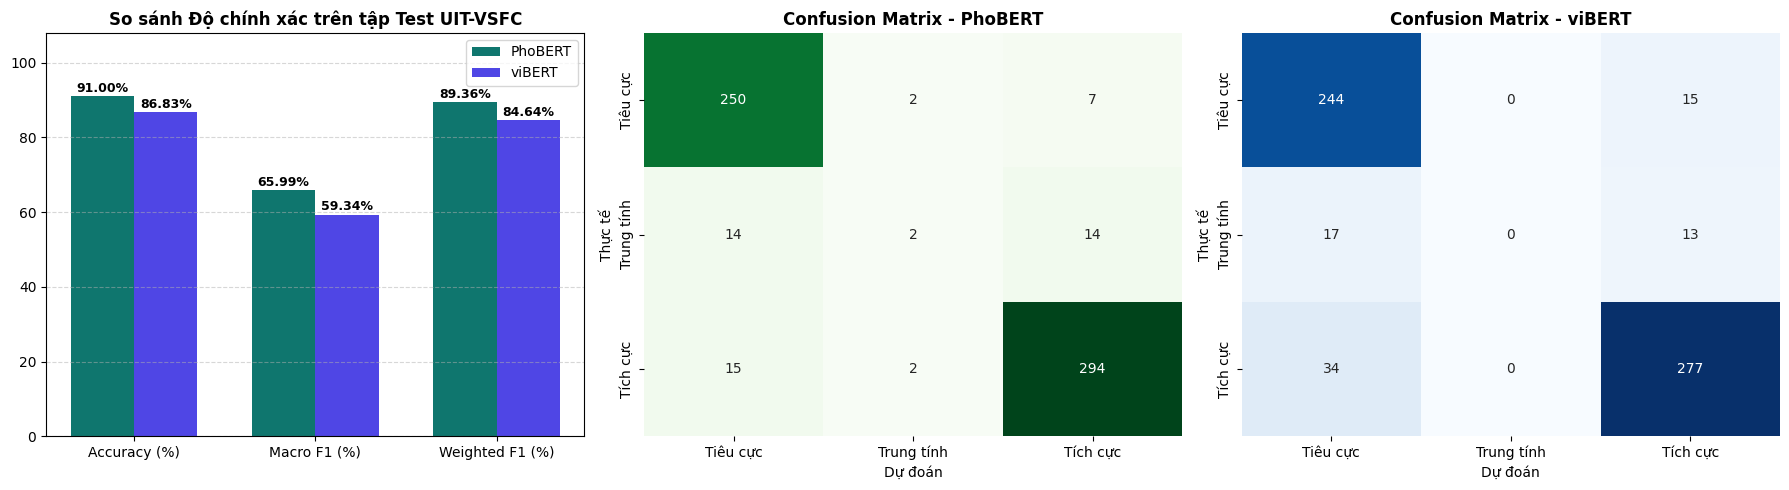

In [11]:
# Vẽ biểu đồ so sánh hiệu năng & ma trận nhầm lẫn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Biểu đồ cột so sánh Accuracy, Macro F1, Weighted F1
metrics = ["Accuracy (%)", "Macro F1 (%)", "Weighted F1 (%)"]
phobert_scores = [res_phobert["accuracy"], res_phobert["macro_f1"], res_phobert["weighted_f1"]]
vibert_scores  = [res_vibert["accuracy"], res_vibert["macro_f1"], res_vibert["weighted_f1"]]

x = np.arange(len(metrics))
width = 0.35
rects1 = axes[0].bar(x - width/2, phobert_scores, width, label="PhoBERT", color="#0F766E")
rects2 = axes[0].bar(x + width/2, vibert_scores, width, label="viBERT", color="#4F46E5")

axes[0].set_title("So sánh Độ chính xác trên tập Test UIT-VSFC", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylim(0, 108)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    h = rect.get_height()
    axes[0].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

# 2. Confusion Matrix PhoBERT
cm_pho = confusion_matrix(res_phobert["y_true"], res_phobert["y_pred"])
sns.heatmap(cm_pho, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Tiêu cực", "Trung tính", "Tích cực"],
            yticklabels=["Tiêu cực", "Trung tính", "Tích cực"], ax=axes[1])
axes[1].set_title("Confusion Matrix - PhoBERT", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")

# 3. Confusion Matrix viBERT
cm_vi = confusion_matrix(res_vibert["y_true"], res_vibert["y_pred"])
sns.heatmap(cm_vi, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Tiêu cực", "Trung tính", "Tích cực"],
            yticklabels=["Tiêu cực", "Trung tính", "Tích cực"], ax=axes[2])
axes[2].set_title("Confusion Matrix - viBERT", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Dự đoán")
axes[2].set_ylabel("Thực tế")

plt.tight_layout()
plt.show()

## 9. Kiểm thử thực tế trên các câu tiếng Việt mẫu (bao gồm từ ghép & tiếng lóng mạng xã hội)
Kiểm tra khả năng dự đoán của cả hai mô hình đã fine-tune trên các câu ví dụ đa dạng.

In [12]:
def predict_sentiment(text, res_dict, use_word_segment=False):
    model = res_dict["trainer"].model
    tokenizer = res_dict["tokenizer"]
    model.eval()

    proc_text = ViTokenizer.tokenize(text) if use_word_segment else text
    inputs = tokenizer(proc_text, return_tensors="pt", truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()[0]
        pred_id = int(np.argmax(probs))

    return LABEL_NAMES[pred_id], round(float(probs[pred_id]) * 100, 2)

test_sentences = [
    "Thầy giảng bài siêu tâm huyết, ví dụ thực tế dễ hiểu cực kỳ!",
    "Phòng máy tính quá nóng, điều hòa hỏng suốt cả học kỳ không ai sửa.",
    "Môn học này có 3 tín chỉ, thi cuối kỳ theo hình thức trắc nghiệm.",
    "Slide bài giảng hơi dài nhưng nội dung ôn tập khá sát đề thi.",
    "học online mạng lag giật tung chảo chả nghe dc j hết trơn"
]

demo_results = []
for sent in test_sentences:
    pho_lbl, pho_conf = predict_sentiment(sent, res_phobert, use_word_segment=True)
    vi_lbl, vi_conf   = predict_sentiment(sent, res_vibert, use_word_segment=False)
    demo_results.append({
        "Câu đầu vào": sent,
        "PhoBERT Dự đoán": f"{pho_lbl} ({pho_conf}%)",
        "viBERT Dự đoán": f"{vi_lbl} ({vi_conf}%)"
    })

display(pd.DataFrame(demo_results))

,Câu đầu vào,PhoBERT Dự đoán,viBERT Dự đoán
0,"Thầy giảng bài siêu tâm huyết, ví dụ thực tế d...",Tích cực (2) (96.29%),Tích cực (2) (95.57%)
1,"Phòng máy tính quá nóng, điều hòa hỏng suốt cả...",Tiêu cực (0) (95.19%),Tiêu cực (0) (92.4%)
2,"Môn học này có 3 tín chỉ, thi cuối kỳ theo hìn...",Tiêu cực (0) (82.75%),Tiêu cực (0) (89.06%)
3,Slide bài giảng hơi dài nhưng nội dung ôn tập ...,Tích cực (2) (66.33%),Tiêu cực (0) (93.29%)
4,học online mạng lag giật tung chảo chả nghe dc...,Tiêu cực (0) (94.62%),Tiêu cực (0) (92.47%)
